<a href="https://colab.research.google.com/github/Shreyap206/Machine_Learning/blob/main/mlp8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder

In [ ]:
df = pd.read_csv("/content/traffic.csv")

print("Original Dataset :")
print(df.head)

Original Dataset :
<bound method NDFrame.head of                   DateTime  Junction  Vehicles           ID
0      2015-11-01 00:00:00         1        15  20151101001
1      2015-11-01 01:00:00         1        13  20151101011
2      2015-11-01 02:00:00         1        10  20151101021
3      2015-11-01 03:00:00         1         7  20151101031
4      2015-11-01 04:00:00         1         9  20151101041
...                    ...       ...       ...          ...
48115  2017-06-30 19:00:00         4        11  20170630194
48116  2017-06-30 20:00:00         4        30  20170630204
48117  2017-06-30 21:00:00         4        16  20170630214
48118  2017-06-30 22:00:00         4        22  20170630224
48119  2017-06-30 23:00:00         4        12  20170630234

[48120 rows x 4 columns]>


In [ ]:
df['Hour'] = pd.to_datetime(df['DateTime']).dt.hour
display(df)

,DateTime,Junction,Vehicles,ID,Hour
0,2015-11-01 00:00:00,1,15,20151101001,0
1,2015-11-01 01:00:00,1,13,20151101011,1
2,2015-11-01 02:00:00,1,10,20151101021,2
3,2015-11-01 03:00:00,1,7,20151101031,3
4,2015-11-01 04:00:00,1,9,20151101041,4
...,...,...,...,...,...
48115,2017-06-30 19:00:00,4,11,20170630194,19
48116,2017-06-30 20:00:00,4,30,20170630204,20
48117,2017-06-30 21:00:00,4,16,20170630214,21
48118,2017-06-30 22:00:00,4,22,20170630224,22


In [ ]:
df = df.drop(columns=['Time', 'Date'], errors='ignore')
display(df.head())

,DateTime,Junction,Vehicles,ID,Hour
0,2015-11-01 00:00:00,1,15,20151101001,0
1,2015-11-01 01:00:00,1,13,20151101011,1
2,2015-11-01 02:00:00,1,10,20151101021,2
3,2015-11-01 03:00:00,1,7,20151101031,3
4,2015-11-01 04:00:00,1,9,20151101041,4


In [ ]:
df['Traffic Situation'] = df['Vehicles'].apply(lambda x: 'Normal' if x <= 15 else 'Heavy')

display(df.head(20))

,DateTime,Junction,Vehicles,ID,Hour,Traffic Situation
0,2015-11-01 00:00:00,1,15,20151101001,0,Normal
1,2015-11-01 01:00:00,1,13,20151101011,1,Normal
2,2015-11-01 02:00:00,1,10,20151101021,2,Normal
3,2015-11-01 03:00:00,1,7,20151101031,3,Normal
4,2015-11-01 04:00:00,1,9,20151101041,4,Normal
5,2015-11-01 05:00:00,1,6,20151101051,5,Normal
6,2015-11-01 06:00:00,1,9,20151101061,6,Normal
7,2015-11-01 07:00:00,1,8,20151101071,7,Normal
8,2015-11-01 08:00:00,1,11,20151101081,8,Normal
9,2015-11-01 09:00:00,1,12,20151101091,9,Normal


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Extract the day of the week from DateTime
df['Day of the week'] = pd.to_datetime(df['DateTime']).dt.day_name()

le = LabelEncoder()
df['Day of the week'] = le.fit_transform(df['Day of the week'])
df['Traffic Situation'] = le.fit_transform(df['Traffic Situation'])

display(df.head(20))

,DateTime,Junction,Vehicles,ID,Hour,Traffic Situation,Day of the week
0,2015-11-01 00:00:00,1,15,20151101001,0,1,3
1,2015-11-01 01:00:00,1,13,20151101011,1,1,3
2,2015-11-01 02:00:00,1,10,20151101021,2,1,3
3,2015-11-01 03:00:00,1,7,20151101031,3,1,3
4,2015-11-01 04:00:00,1,9,20151101041,4,1,3
5,2015-11-01 05:00:00,1,6,20151101051,5,1,3
6,2015-11-01 06:00:00,1,9,20151101061,6,1,3
7,2015-11-01 07:00:00,1,8,20151101071,7,1,3
8,2015-11-01 08:00:00,1,11,20151101081,8,1,3
9,2015-11-01 09:00:00,1,12,20151101091,9,1,3


In [ ]:
x = df.drop(columns=['Traffic Situation'])
y = df['Traffic Situation']

In [ ]:
# Drop non-numerical column 'DateTime' for feature selection
x_numeric = x.drop(columns=['DateTime'], errors='ignore')

selector = SelectKBest(score_func=f_classif, k=4)
x_selected = selector.fit_transform(x_numeric, y)
selected_features = x_numeric.columns[selector.get_support()]

print("\nSelected Features :")
print(selected_features)


Selected Features :
Index(['Junction', 'Vehicles', 'ID', 'Hour'], dtype='object')


In [ ]:
x_selected = pd.DataFrame(
    x_selected,
    columns=selected_features
)
display(x_selected.head())

,Junction,Vehicles,ID,Hour
0,1,15,20151101001,0
1,1,13,20151101011,1
2,1,10,20151101021,2
3,1,7,20151101031,3
4,1,9,20151101041,4


In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x_selected,y,test_size=0.2,random_state=42)

In [ ]:
model = DecisionTreeClassifier(
    criterion= 'gini',
    random_state=42
)
model.fit(x_train,y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
root_index = model.tree_.feature[0]
root_node = x_selected.columns[root_index]

print("\nRoot Node :")
print(root_node)


Root Node :
Vehicles


In [ ]:
# Generate predictions on the test set first
y_pred = model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy :")
print(accuracy)


Accuracy :
1.0


In [ ]:
print("\nConfusion Matrix :")
print(confusion_matrix(y_test, y_pred))


Confusion Matrix :
[[4717    0]
 [   0 4907]]


In [ ]:
new_traffic = x_selected.iloc[[0]]
prediction = model.predict(new_traffic)

if prediction[0]==1:
  print("\ntraffic prediction : Heavy")
else:
  print("\ntraffic prediction : Normal")


traffic prediction : Heavy


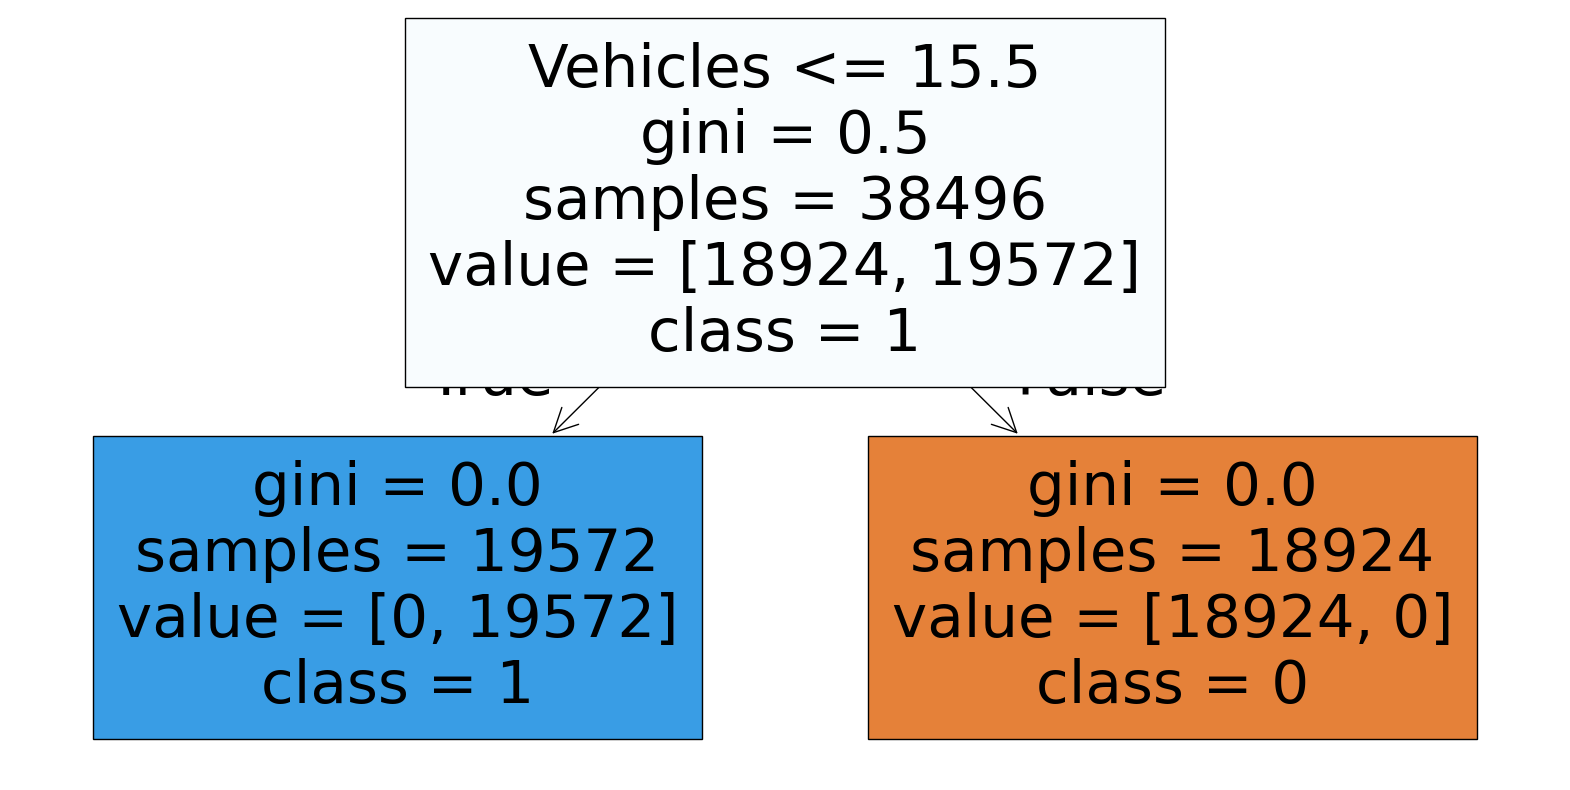

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(model,
          feature_names = selected_features,
          class_names =[str(c) for c in model.classes_],
          filled =True,
          max_depth=3
          )
plt.show()